### Sentiment Analysis
##### Objective: Build a machine learning model that classifies the sentiment of text data (positive, negative, or neutral), providing insights into public opinion or customer feedback.


In [1]:
# import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data
tweet = pd.read_csv('Tweets.csv')

In [2]:
# Data info
print(tweet.info())
print(f'\nMissing values:\n {tweet.isna().sum()}')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  object 
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   object 
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  object 
 6   airline_sentiment_gold        40 non-null     object 
 7   name                          14640 non-null  object 
 8   negativereason_gold           32 non-null     object 
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  object 
 11  tweet_coord                   1019 non-null   object 
 12  tweet_created                 14640 non-null  object 
 13  t

In [3]:
tweet.head(3)

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)


airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64


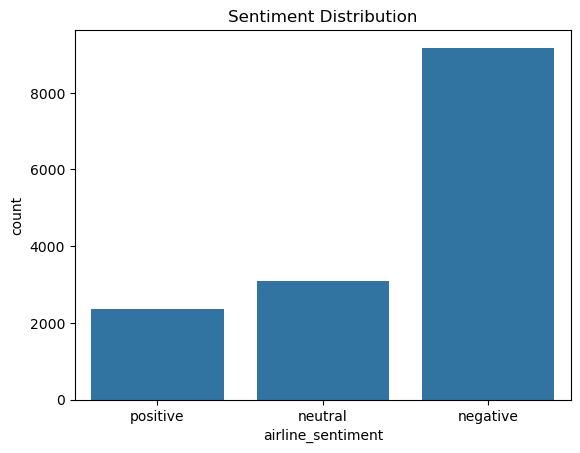

In [4]:
# inspect class distribution
print(tweet['airline_sentiment'].value_counts())
sns.countplot(data=tweet, x='airline_sentiment', order=['positive', 'neutral', 'negative'])
plt.title('Sentiment Distribution')
plt.show()

In [5]:
import re
import string
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = text.lower()
    text = re.sub(r'@\w+', '', text)  # remove @mentions
    text = re.sub(r'http\S+', '', text)  # remove URLs
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\d+', '', text)  # remove numbers
    tokens = text.split()
    tokens = [w for w in tokens if w not in stop_words]
    return ' '.join(tokens)

tweet['clean_text'] = tweet['text'].apply(clean_text)
tweet[['text', 'clean_text']].head()

[nltk_data] Error loading stopwords: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>


,text,clean_text
0,@VirginAmerica What @dhepburn said.,said
1,@VirginAmerica plus you've added commercials t...,plus youve added commercials experience tacky
2,@VirginAmerica I didn't today... Must mean I n...,didnt today must mean need take another trip
3,@VirginAmerica it's really aggressive to blast...,really aggressive blast obnoxious entertainmen...
4,@VirginAmerica and it's a really big bad thing...,really big bad thing


**TF-IDF (Term Frequency-Inverse Document Frequency)** converts text into numeric features by weighing each word based on how often it appears in a tweet versus how common it is across all tweets. Words that appear frequently in one tweet but rarely elsewhere (e.g., "terible", "amazing") get high scores, while common words that appear everywhere get low scores. This lets the model focus on words that actually carry sentiment signal.

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)
X = tfidf.fit_transform(tweet['clean_text'])
Y = tweet['airline_sentiment']

print(X.shape)

(14640, 5000)


In [7]:
# Train/test split
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)

print(X_train.shape, X_test.shape)

(11712, 5000) (2928, 5000)


In [8]:
# Train the two classifiers
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

nb = MultinomialNB()
nb.fit(X_train, Y_train)

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, Y_train)

print('Both models trained')

Both models trained


-- Naive Bayes --
              precision    recall  f1-score   support

    negative       0.72      0.98      0.83      1835
     neutral       0.75      0.27      0.40       620
    positive       0.84      0.34      0.49       473

    accuracy                           0.73      2928
   macro avg       0.77      0.53      0.57      2928
weighted avg       0.75      0.73      0.69      2928



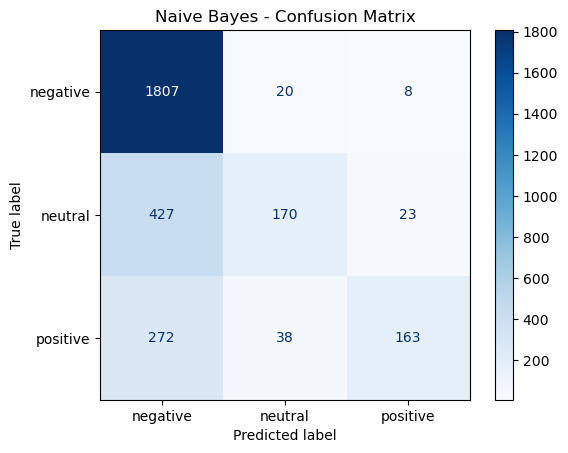

-- Logistic Regression --
              precision    recall  f1-score   support

    negative       0.80      0.94      0.86      1835
     neutral       0.66      0.49      0.56       620
    positive       0.83      0.55      0.66       473

    accuracy                           0.78      2928
   macro avg       0.76      0.66      0.69      2928
weighted avg       0.77      0.78      0.77      2928



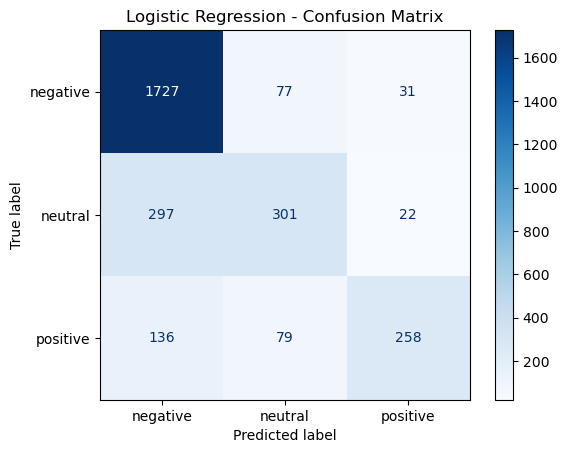

In [9]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

models = {'Naive Bayes': nb, 'Logistic Regression': lr}

for name, model in models.items():
    preds = model.predict(X_test)
    print(f'-- {name} --')
    print(classification_report(Y_test, preds))

    cm = confusion_matrix(Y_test, preds, labels=model.classes_)
    disp = ConfusionMatrixDisplay(cm, display_labels=model.classes_)
    disp.plot(cmap='Blues')
    plt.title(f'{name} - Confusion Matrix')
    plt.show()

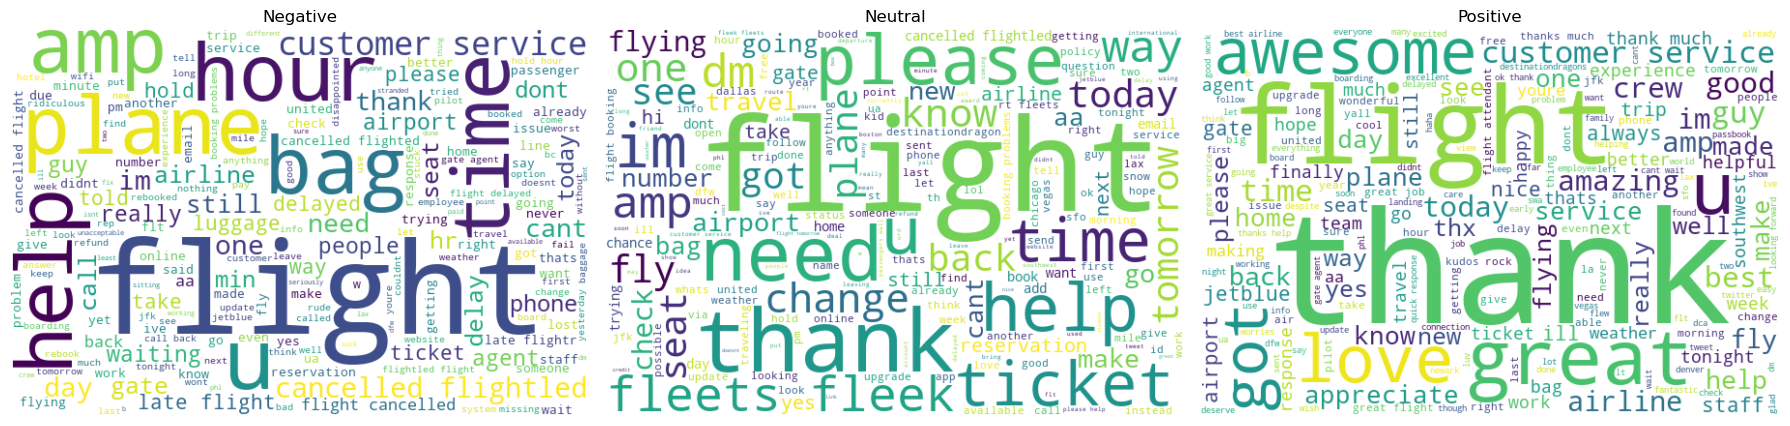

In [10]:
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, sentiment in zip(axes, ['negative', 'neutral', 'positive']):
    text = ' '.join(tweet[tweet['airline_sentiment'] == sentiment]['clean_text']) 
    wc = WordCloud(width=600, height=400, background_color='white').generate(text)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(sentiment.capitalize())
    ax.axis('off')
plt.tight_layout()
plt.show()

In [11]:
import numpy as np

lr_preds = lr.predict(X_test)

# Get indices of test set (since X_test is a sparse matrix, we need original indices)
test_indices = Y_test.index

# Find misclassified examples
misclassified_mask = lr_preds != Y_test.values
misclassified_indices = test_indices[misclassified_mask]

# Sample 5 misclassified examples
sample_errors = tweet.loc[misclassified_indices].sample(5, random_state=42)
sample_preds = lr_preds[misclassified_mask][:5] if len(misclassified_indices) >= 5 else lr_preds[misclassified_mask]

for idx, (i, row) in enumerate(sample_errors.iterrows()):
    predicted_label = lr.predict(tfidf.transform([row['clean_text']]))[0]
    print(f'Tweet: {row['text']}')
    print(f'True label: {row['airline_sentiment']} | Predicted: {predicted_label}')
    print("-" * 60)

Tweet: @AmericanAir i want to change my flight for next week, they will still charge me. Waiting for fligt status
True label: neutral | Predicted: negative
------------------------------------------------------------
Tweet: @united holy high speed internet batman!  Speeds at United Club at IAD are insanely fast!  Thanks
True label: positive | Predicted: neutral
------------------------------------------------------------
Tweet: @VirginAmerica Really missed a prime opportunity for Men Without Hats parody, there. https://t.co/mWpG7grEZP
True label: neutral | Predicted: negative
------------------------------------------------------------
Tweet: @AmericanAir its Adolfo Garcia
True label: neutral | Predicted: negative
------------------------------------------------------------
Tweet: @JetBlue TA off site at #thelodge. Should be a fun day. @YeniettElswood @AndrewBiga @CodyCleverly @HeidiMacey @motherpollock
True label: positive | Predicted: negative
----------------------------------------

**Conclusion**

Logistic Regression outperformed Naive Bayes across all metrics (78% vs 73% accurancy), particully on the minority neutral and positive classes, where Naive Bayes' strong bias toward "negative" (the majority class) hurt its recall. This suggests Logistic Regression handles the class imbalance in this dataset more gracefully.

**Real-world application:** This kind of pipeline could power an airline's customer service triage system - automatically flagging negative tweets for urgent response, routing neutral inquires to a general support queue, and surfacing positive feedback for marketing or employee recognition. Error analysis shows the model struggles with sarcasm, very short tweets, and posts diluted by @mentions, so a production system would benefit from combining this rule-based filters (e.g., minimum word count) and possibly a more context-aware model (like a fine-tuned transformer) for higher-stakes decisions.